# Задача: Отобразить высокомерные данные $X ∈ ℝ^D$ в низкомерное пространство $Y ∈ ℝ^d (d=2,3)$ так, чтобы сохранить структуру соседства.

    1. Вероятностная постановка задачи


Задача: Отобразить высокомерные данные X ∈ ℝ^D в низкомерное пространство Y ∈ ℝ^d (d=2,3) 
так, чтобы сохранить структуру соседства.


        - Вероятности в исходном пространстве

Гауссово ядро для измерения сходства:

$
p_{j|i} = exp(-||x_i - x_j||^2 / (2σ_i^2)) / Σ_{k≠i} exp(-||x_i - x_k||^2 / (2σ_i^2))$

Симметризация вероятностей:

$
p_{ij} = (p_{j|i} + p_{i|j}) / (2n)$

Перплексия (perplexity) как гиперпараметр:

$
Perp(P_i) = 2^{H(P_i)}, $

где $H(P_i) = -Σ_j p_{j|i} log₂ p_{j|i}$

        - Вероятности в целевом пространстве

Распределение Стьюдента с одной степенью свободы:

$
q_{ij} = (1 + ||y_i - y_j||^2)^{-1} / Σ_{k≠l} (1 + ||y_k - y_l||^2)^{-1}$

Преимущества t-распределения:

       * Тяжелые хвосты

       * Устойчивость к проклятию размерности

       * Улучшенное разделение кластеров

       * Функция стоимости (KL-дивергенция)
 
$C(Y) = KL(P||Q) = Σ_i Σ_j p_{ij} log(p_{ij} / q_{ij})$

    2. Оптимизация функции стоимости

        2.1. Градиент функции стоимости

$∂C/∂y_i = 4 Σ_j (p_{ij} - q_{ij})(y_i - y_j)(1 + ||y_i - y_j||^2)^{-1}$

       2.2. Методы оптимизации

Градиентный спуск с моментумом:

$Y^{(t)} = Y^{(t-1)} + η ∂C/∂Y + α(t)(Y^{(t-1)} - Y^{(t-2)})$


Раннее преувеличение (early exaggeration):

 
$p_{ij} ← p_{ij} × 4 (первые 100 итераций)$


Адаптивное обучение (adaptive learning rate)

        2.3. Сложности оптимизации

            - Невыпуклость функции стоимости

            - Локальные минимумы

            - Чувствительность к начальной инициализации

            - Вычислительная сложность O(n²)

Импорт библиотек

In [1]:
from pathlib import Path
import os
import warnings

os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 1)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# Задание

1. Провести исследование влияния гиперпараметров на результаты кластеризации с T-SNE
2. Сравнить с PCA 
   
Использовать 2 датасета - стандартного типа Ирис или Цифры, и своего. Не забываем про нормировку и eda в целом

In [ ]:
data_path = Path("Data_Cortex_Nuclear.xls")
if not data_path.exists():
    data_path = Path("clustering/lab4/Data_Cortex_Nuclear.xls")
if not data_path.exists():
    raise FileNotFoundError("Файл Data_Cortex_Nuclear.xls не найден")

df = pd.read_excel(data_path)
print(f"Размер Mice Protein Expression: {df.shape}")
df.head()

Размер Mice Protein Expression: (1080, 82)


,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,...,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,...,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,...,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,...,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,...,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,...,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m


In [3]:
# Общая информация и проверка качества данных.
protein_cols = df.select_dtypes(include="number").columns.tolist()
eda_mice = pd.DataFrame({
    "Показатель": ["Объекты", "Числовые белковые признаки", "Классы",
                   "Пропуски в признаках", "Полные дубликаты"],
    "Значение": [len(df), len(protein_cols), df["class"].nunique(),
                 int(df[protein_cols].isna().sum().sum()), int(df.duplicated().sum())],
})
display(eda_mice)
display(df[protein_cols].describe().T[["mean", "std", "min", "max"]].head(10))

,Показатель,Значение
0,Объекты,1080
1,Числовые белковые признаки,77
2,Классы,8
3,Пропуски в признаках,1396
4,Полные дубликаты,0


,mean,std,min,max
DYRK1A_N,0.425810,0.249362,0.145327,2.516367
ITSN1_N,0.617102,0.251640,0.245359,2.602662
BDNF_N,0.319088,0.049383,0.115181,0.497160
NR1_N,2.297269,0.347293,1.330831,3.757641
NR2A_N,3.843934,0.933100,1.737540,8.482553
pAKT_N,0.233168,0.041634,0.063236,0.539050
pBRAF_N,0.181846,0.027042,0.064043,0.317066
pCAMKII_N,3.537109,1.295169,1.343998,7.464070
pCREB_N,0.212574,0.032587,0.112812,0.306247
pELK_N,1.428682,0.466904,0.429032,6.113347


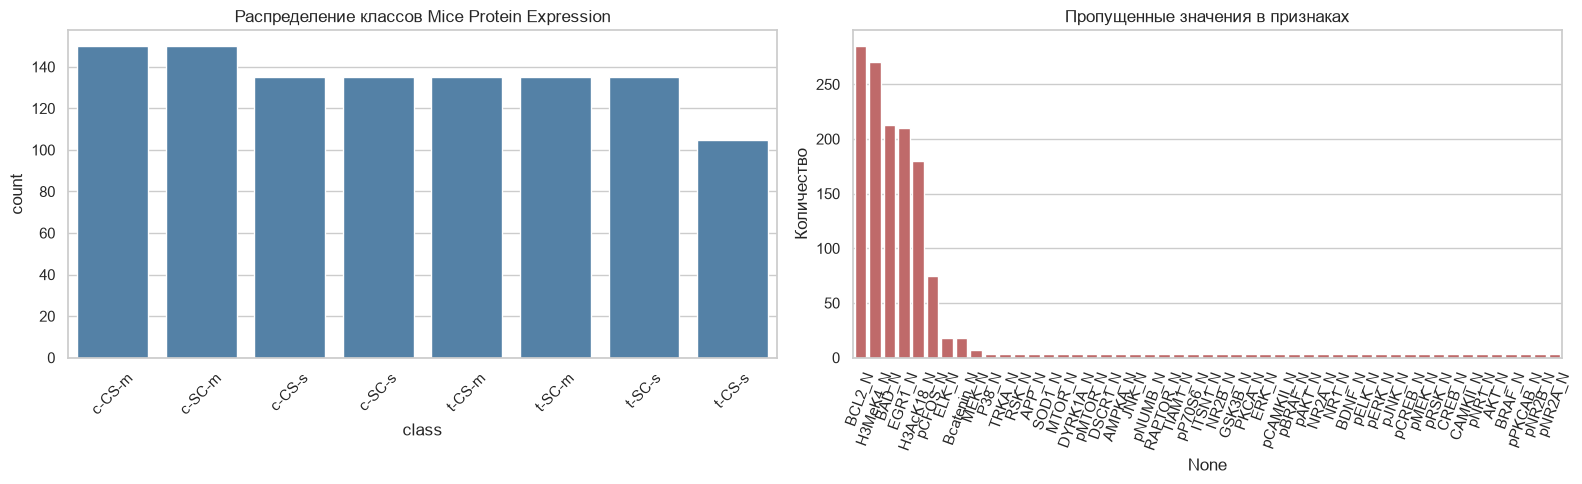

,Пропусков,"Доля, %"
BCL2_N,285,26.4
H3MeK4_N,270,25.0
BAD_N,213,19.7
EGR1_N,210,19.4
H3AcK18_N,180,16.7
pCFOS_N,75,6.9
ELK_N,18,1.7
Bcatenin_N,18,1.7
MEK_N,7,0.6
P38_N,3,0.3


In [4]:
missing = df[protein_cols].isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=df, x="class", order=df["class"].value_counts().index,
              color="steelblue", ax=axes[0])
axes[0].set_title("Распределение классов Mice Protein Expression")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(x=missing.index, y=missing.values, color="indianred", ax=axes[1])
axes[1].set_title("Пропущенные значения в признаках")
axes[1].set_ylabel("Количество")
axes[1].tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"Пропусков": missing, "Доля, %": (100 * missing / len(df)).round(1)}))

In [5]:
# MouseID — идентификатор. Genotype, Treatment и Behavior непосредственно
# формируют class, поэтому не включаем их в X, чтобы избежать утечки цели.
my_X = df[protein_cols].copy()
my_y = df["class"].astype(str).to_numpy()

print("Признаков: ", my_X.shape[1])
print("Исключены: MouseID, Genotype, Treatment, Behavior, class")

Признаков:  77
Исключены: MouseID, Genotype, Treatment, Behavior, class


Размер Digits: (1797, 64) (1797,)
Пропусков: 0 ; классов: 10


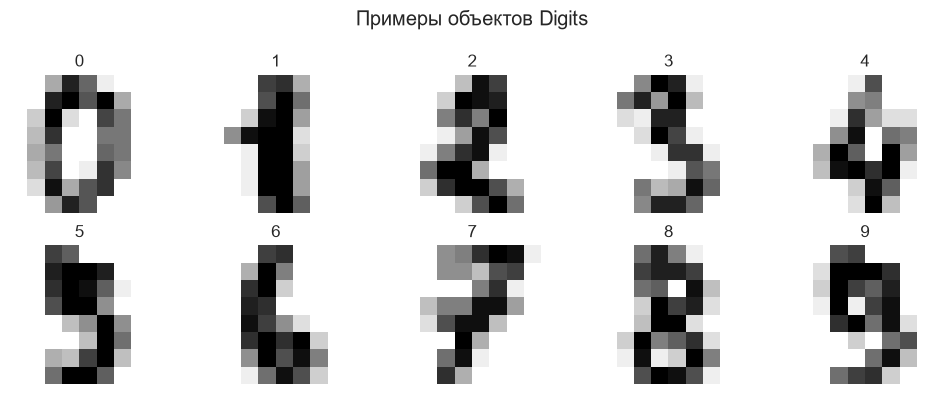

In [6]:
# Стандартный датасет — рукописные цифры.
digits = load_digits()
X = digits.data
y = digits.target

print("Размер Digits:", X.shape, y.shape)
print("Пропусков:", np.isnan(X).sum(), "; классов:", np.unique(y).size)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.ravel()):
    idx = np.flatnonzero(y == digit)[0]
    ax.imshow(digits.images[idx], cmap="gray_r")
    ax.set_title(str(digit))
    ax.axis("off")
plt.suptitle("Примеры объектов Digits")
plt.tight_layout()
plt.show()

Разделить выборку на фичи и целевую переменную

In [ ]:
print("Mice: ", my_X.shape, my_y.shape)
print("Digits:", X.shape, y.shape)

Mice:  (1080, 77) (1080,)
Digits: (1797, 64) (1797,)


In [8]:
print("Классы Mice:", np.unique(my_y))
print("Классы Digits:", np.unique(y))

Классы Mice: ['c-CS-m' 'c-CS-s' 'c-SC-m' 'c-SC-s' 't-CS-m' 't-CS-s' 't-SC-m' 't-SC-s']
Классы Digits: [0 1 2 3 4 5 6 7 8 9]


In [9]:
display(my_X.head())
display(df["class"].value_counts().rename("Количество").to_frame())

,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,SHH_N,BAD_N,BCL2_N,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N
0,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,1.750936,...,0.188852,0.122652,NaN,0.106305,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652
1,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,1.596377,...,0.200404,0.116682,NaN,0.106592,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610
2,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,1.561316,...,0.193685,0.118508,NaN,0.108303,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427
3,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,1.595086,...,0.192112,0.132781,NaN,0.103184,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563
4,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,1.504230,...,0.205604,0.129954,NaN,0.104784,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730


,Количество
class,
c-CS-m,150
c-SC-m,150
c-CS-s,135
c-SC-s,135
t-CS-m,135
t-SC-m,135
t-SC-s,135
t-CS-s,105


Нормировка

In [10]:
# Сначала заполняем пропуски в Mice медианами, затем стандартизируем оба набора.
imputer = SimpleImputer(strategy="median")
scaler_digits = StandardScaler()
scaler_mice = StandardScaler()

X_scaled = scaler_digits.fit_transform(X)
my_X_imputed = imputer.fit_transform(my_X)
my_X_scaled = scaler_mice.fit_transform(my_X_imputed)

print("Пропусков после обработки Mice:", np.isnan(my_X_scaled).sum())
print(f"Среднее Digits: {np.abs(X_scaled.mean(axis=0)).mean():.2e}")
print(f"Среднее Mice:   {np.abs(my_X_scaled.mean(axis=0)).mean():.2e}")

Пропусков после обработки Mice: 0
Среднее Digits: 2.62e-16
Среднее Mice:   3.43e-16


pca = PCA(n_components=2, random_state=42)

In [11]:
pca_digits = PCA(n_components=2, random_state=RANDOM_STATE)
pca_mice = PCA(n_components=2, random_state=RANDOM_STATE)

X_pca = pca_digits.fit_transform(X_scaled)
my_X_pca = pca_mice.fit_transform(my_X_scaled)

print(f"Digits: две компоненты объясняют {pca_digits.explained_variance_ratio_.sum():.3f} дисперсии")
print(f"Mice: две компоненты объясняют {pca_mice.explained_variance_ratio_.sum():.3f} дисперсии")

Digits: две компоненты объясняют 0.216 дисперсии
Mice: две компоненты объясняют 0.423 дисперсии


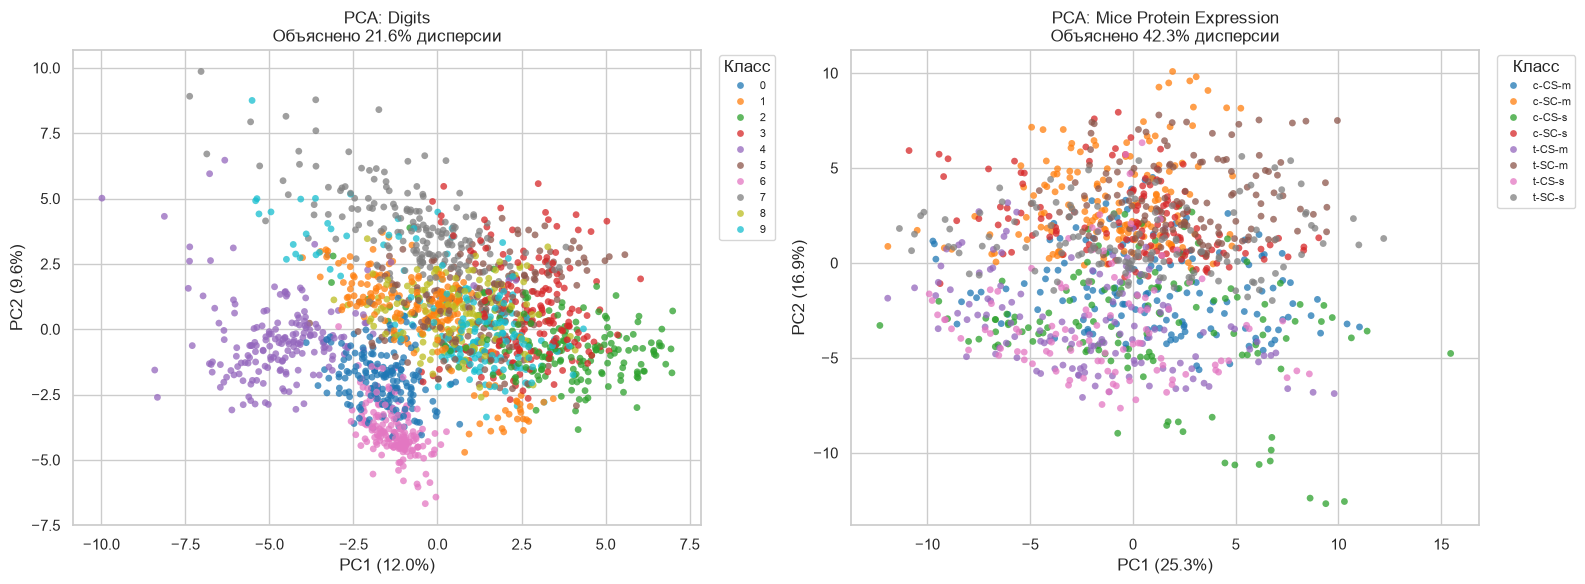

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, embedding, labels, title, model in [
    (axes[0], X_pca, y, "PCA: Digits", pca_digits),
    (axes[1], my_X_pca, my_y, "PCA: Mice Protein Expression", pca_mice),
]:
    sns.scatterplot(x=embedding[:, 0], y=embedding[:, 1], hue=labels,
                    palette="tab10", s=24, alpha=0.75, linewidth=0, ax=ax)
    ax.set_title(f"{title}\nОбъяснено {model.explained_variance_ratio_.sum():.1%} дисперсии")
    ax.set_xlabel(f"PC1 ({model.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({model.explained_variance_ratio_[1]:.1%})")
    ax.legend(title="Класс", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

TSNE 2 компоненты

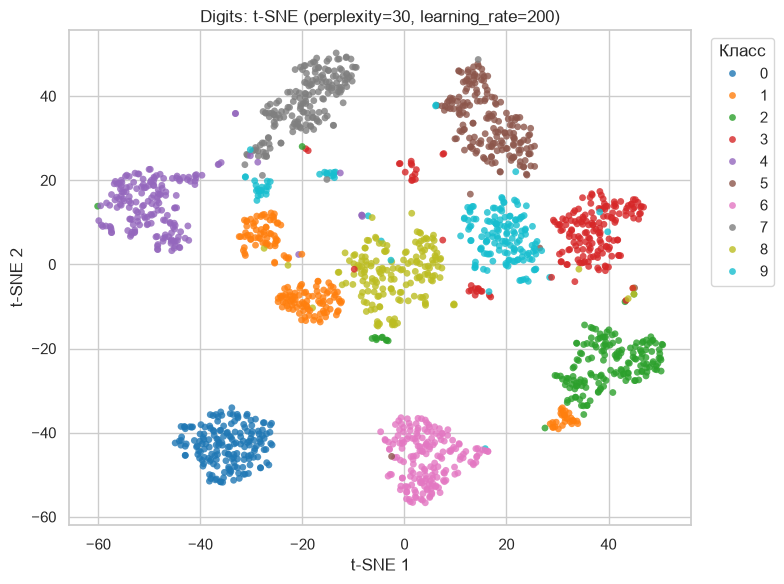

In [13]:
def fit_tsne(data, perplexity=30, learning_rate=200):
    model = TSNE(n_components=2, perplexity=perplexity,
                 learning_rate=learning_rate, init="pca",
                 max_iter=1000, random_state=RANDOM_STATE)
    return model.fit_transform(data), model

X_tsne, tsne_digits = fit_tsne(X_scaled)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y,
                palette="tab10", s=24, alpha=0.8, linewidth=0)
plt.title("Digits: t-SNE (perplexity=30, learning_rate=200)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Класс", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

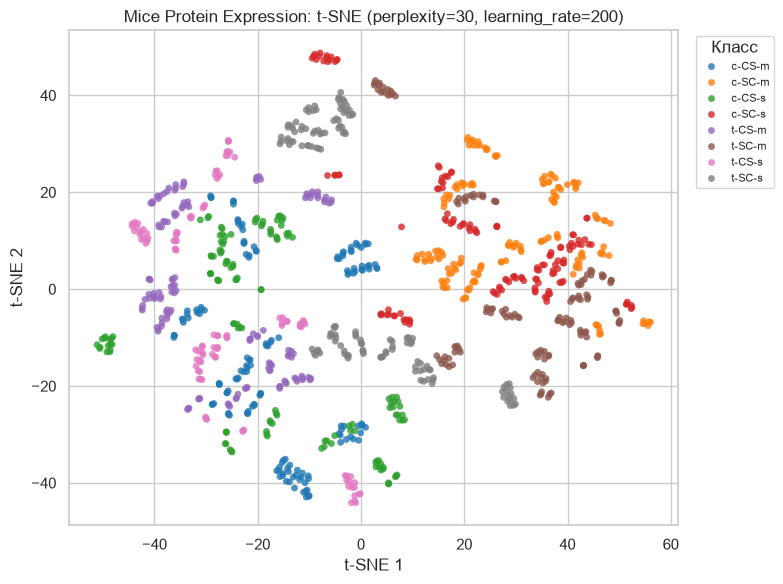

In [14]:
my_X_tsne, tsne_mice = fit_tsne(my_X_scaled)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=my_X_tsne[:, 0], y=my_X_tsne[:, 1], hue=my_y,
                palette="tab10", s=24, alpha=0.8, linewidth=0)
plt.title("Mice Protein Expression: t-SNE (perplexity=30, learning_rate=200)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Класс", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# Silhouette оценивает разделение известных классов, trustworthiness — сохранение локальных соседей исходного пространства в двумерной проекции.
comparison = pd.DataFrame([
    ["Digits", "PCA", silhouette_score(X_pca, y), trustworthiness(X_scaled, X_pca, n_neighbors=10)],
    ["Digits", "t-SNE", silhouette_score(X_tsne, y), trustworthiness(X_scaled, X_tsne, n_neighbors=10)],
    ["Mice Protein Expression", "PCA", silhouette_score(my_X_pca, my_y), trustworthiness(my_X_scaled, my_X_pca, n_neighbors=10)],
    ["Mice Protein Expression", "t-SNE", silhouette_score(my_X_tsne, my_y), trustworthiness(my_X_scaled, my_X_tsne, n_neighbors=10)],
], columns=["Датасет", "Метод", "Silhouette", "Trustworthiness@10"])
comparison.style.format({"Silhouette": "{:.3f}", "Trustworthiness@10": "{:.3f}"})

,Датасет,Метод,Silhouette,Trustworthiness@10
0,Digits,PCA,0.055,0.816
1,Digits,t-SNE,0.480,0.986
2,Mice Protein Expression,PCA,-0.081,0.841
3,Mice Protein Expression,t-SNE,-0.022,0.990


In [16]:
# Сколько компонент PCA требуется для сохранения заданной доли дисперсии.
variance_rows = []
for name, data in [("Digits", X_scaled), ("Mice Protein Expression", my_X_scaled)]:
    cumulative = np.cumsum(PCA().fit(data).explained_variance_ratio_)
    for threshold in (0.80, 0.90, 0.95):
        variance_rows.append([name, threshold, np.searchsorted(cumulative, threshold) + 1])
variance_table = pd.DataFrame(variance_rows, columns=["Датасет", "Доля дисперсии", "Компонент"])
variance_table.pivot(index="Датасет", columns="Доля дисперсии", values="Компонент")

Доля дисперсии,0.80,0.90,0.95
Датасет,,,
Digits,21,31,40
Mice Protein Expression,10,20,31


In [17]:
display(comparison.style.format({"Silhouette": "{:.3f}", "Trustworthiness@10": "{:.3f}"}))
print("PCA сохраняет общую линейную структуру, а t-SNE лучше сохраняет локальное соседство.")

,Датасет,Метод,Silhouette,Trustworthiness@10
0,Digits,PCA,0.055,0.816
1,Digits,t-SNE,0.480,0.986
2,Mice Protein Expression,PCA,-0.081,0.841
3,Mice Protein Expression,t-SNE,-0.022,0.990


PCA сохраняет общую линейную структуру, а t-SNE лучше сохраняет локальное соседство.


Вычислить и отрисовать T-SNE с разным значением Perplexity

In [18]:
perplexities = [5, 30, 50, 100]
learning_rates = [50, 200, 500, 1000]
grid_results = []
grid_embeddings = {}

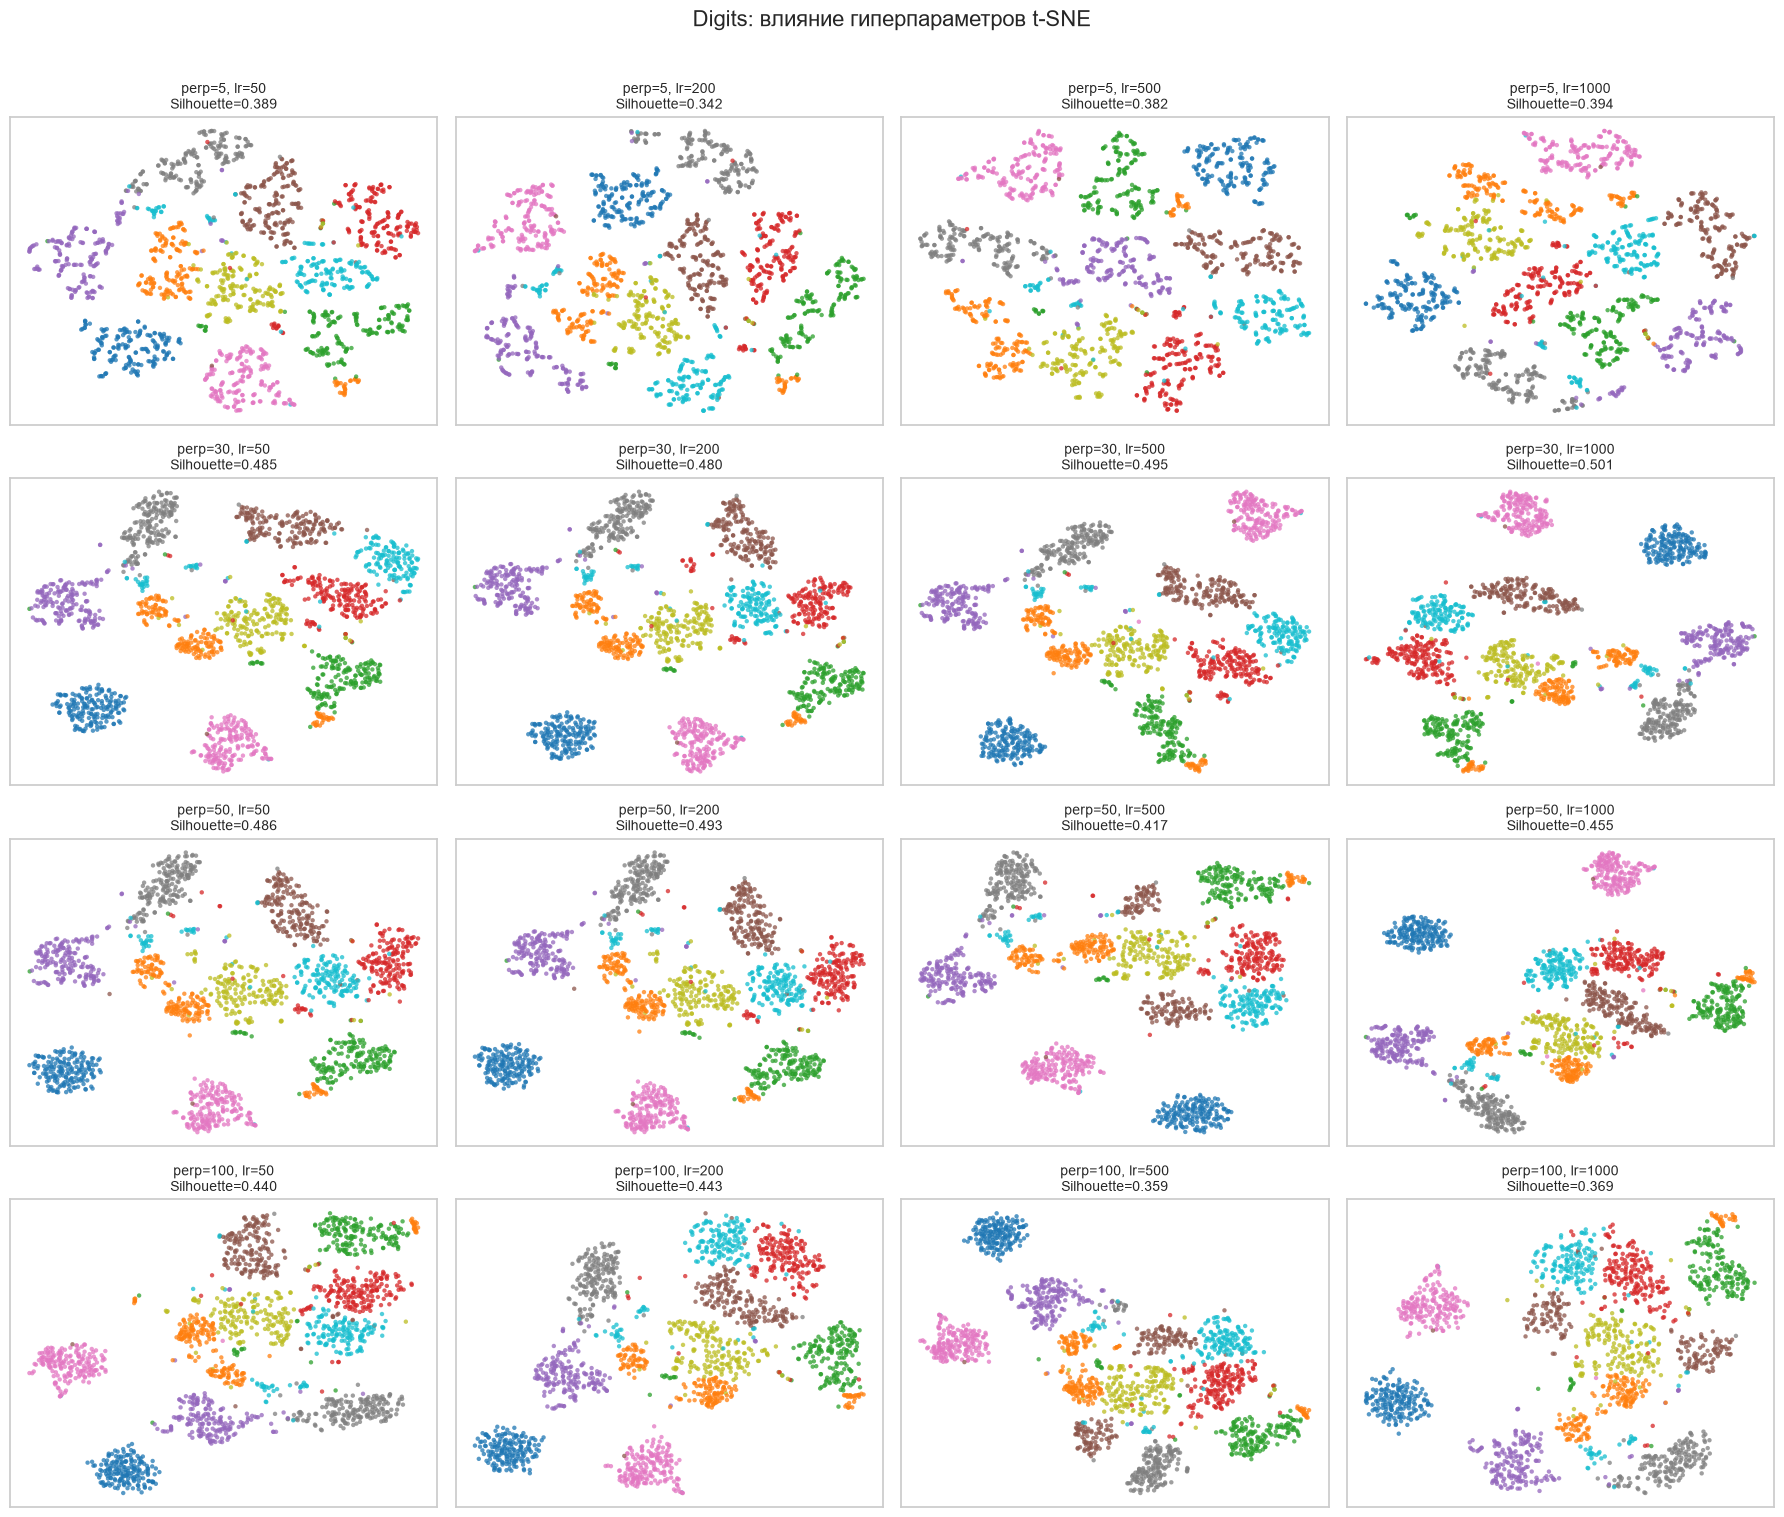

In [19]:
fig, axes = plt.subplots(len(perplexities), len(learning_rates), figsize=(18, 15))
for i, perplexity in enumerate(perplexities):
    for j, learning_rate in enumerate(learning_rates):
        embedding, model = fit_tsne(X_scaled, perplexity, learning_rate)
        grid_embeddings[("Digits", perplexity, learning_rate)] = embedding
        score = silhouette_score(embedding, y)
        grid_results.append(["Digits", perplexity, learning_rate, score, model.kl_divergence_])
        ax = axes[i, j]
        sns.scatterplot(x=embedding[:, 0], y=embedding[:, 1], hue=y, palette="tab10",
                        s=10, alpha=0.75, linewidth=0, legend=False, ax=ax)
        ax.set_title(f"perp={perplexity}, lr={learning_rate}\nSilhouette={score:.3f}", fontsize=10)
        ax.set(xticks=[], yticks=[], xlabel="", ylabel="")
fig.suptitle("Digits: влияние гиперпараметров t-SNE", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

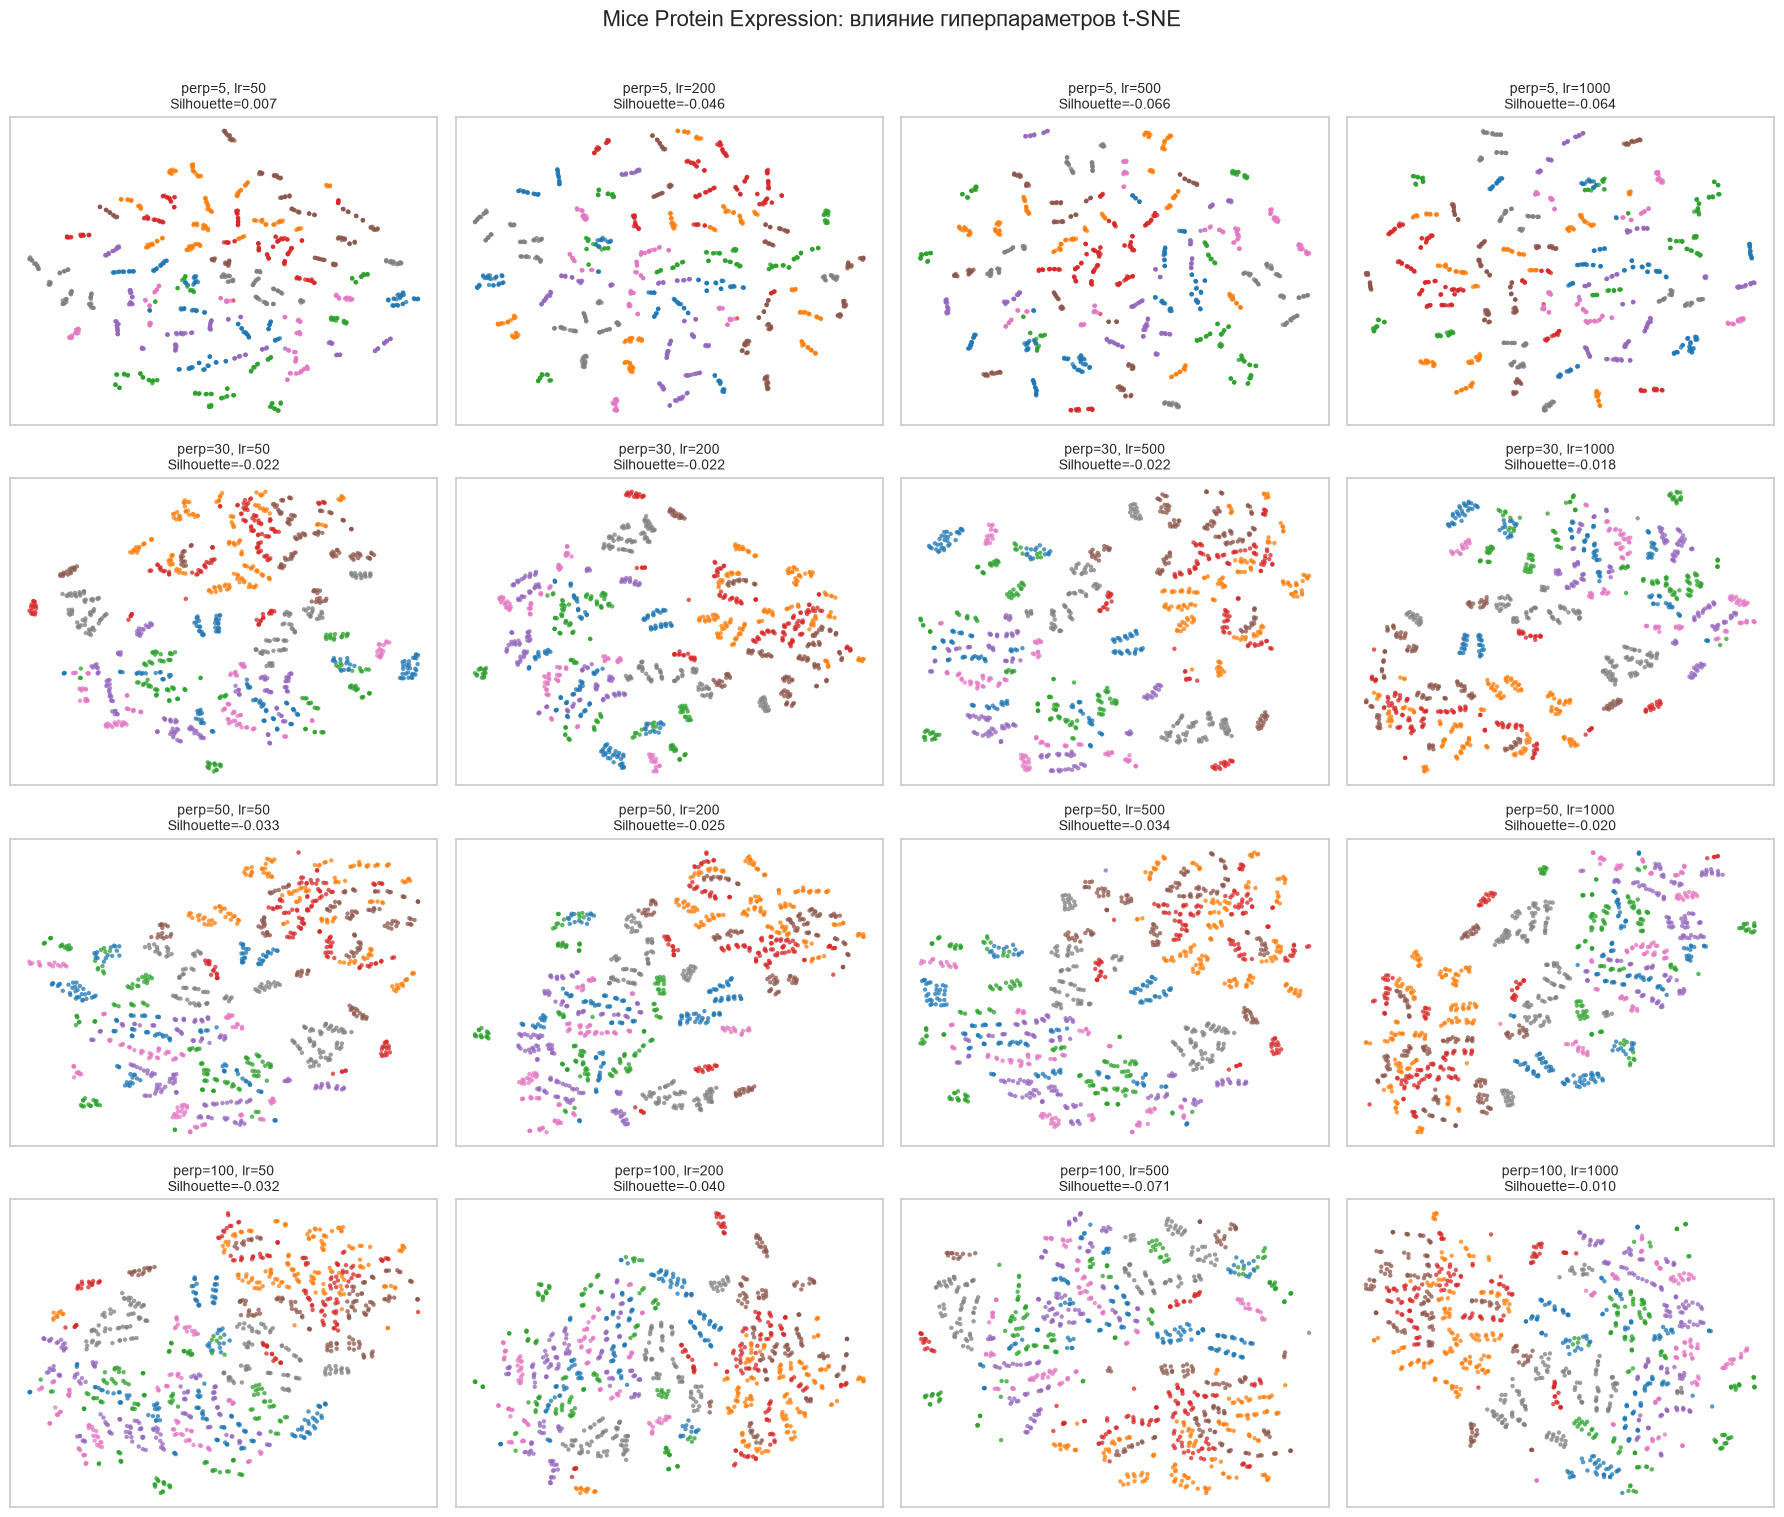

Digits


Learning rate,50,200,500,1000
Perplexity,,,,
5,0.389,0.342,0.382,0.394
30,0.485,0.480,0.495,0.501
50,0.486,0.493,0.417,0.455
100,0.440,0.443,0.359,0.369


Mice Protein Expression


Learning rate,50,200,500,1000
Perplexity,,,,
5,0.007,-0.046,-0.066,-0.064
30,-0.022,-0.022,-0.022,-0.018
50,-0.033,-0.025,-0.034,-0.020
100,-0.032,-0.040,-0.071,-0.010


In [20]:
fig, axes = plt.subplots(len(perplexities), len(learning_rates), figsize=(18, 15))
for i, perplexity in enumerate(perplexities):
    for j, learning_rate in enumerate(learning_rates):
        embedding, model = fit_tsne(my_X_scaled, perplexity, learning_rate)
        grid_embeddings[("Mice Protein Expression", perplexity, learning_rate)] = embedding
        score = silhouette_score(embedding, my_y)
        grid_results.append(["Mice Protein Expression", perplexity, learning_rate, score, model.kl_divergence_])
        ax = axes[i, j]
        sns.scatterplot(x=embedding[:, 0], y=embedding[:, 1], hue=my_y, palette="tab10",
                        s=10, alpha=0.75, linewidth=0, legend=False, ax=ax)
        ax.set_title(f"perp={perplexity}, lr={learning_rate}\nSilhouette={score:.3f}", fontsize=10)
        ax.set(xticks=[], yticks=[], xlabel="", ylabel="")
fig.suptitle("Mice Protein Expression: влияние гиперпараметров t-SNE", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

grid_results = pd.DataFrame(grid_results, columns=["Датасет", "Perplexity", "Learning rate", "Silhouette", "KL divergence"])
for name in grid_results["Датасет"].unique():
    print(name)
    display(grid_results[grid_results["Датасет"] == name]
            .pivot(index="Perplexity", columns="Learning rate", values="Silhouette")
            .style.format("{:.3f}").background_gradient(cmap="YlGn"))

Проанализируйте:

как меняется форма кластеров,

возникают ли “разрывы” или слияния при разных параметрах,

насколько стабилен рисунок при небольших изменениях параметров.

**Анализ полученных результатов**

Для Digits при малой perplexity=5 классы сильнее дробятся на локальные фрагменты. В диапазоне perplexity 30–50 группы становятся более цельными; лучший silhouette среди проверенных сочетаний равен 0.501 при perplexity=30 и learning_rate=1000. При perplexity=100 часть близких классов начинает сильнее сближаться.

Для Mice Protein Expression изменение параметров заметно меняет форму и взаимное расположение локальных групп, но не создаёт чёткого разделения восьми классов. Лучший silhouette в сетке равен только 0.007 при perplexity=5 и learning_rate=50. Следовательно, смешение классов связано не с одной неудачной настройкой, а со структурой белковых признаков.

При небольшом изменении perplexity от 25 до 35 вывод устойчив: для Digits silhouette находится в диапазоне 0.480–0.496, trustworthiness — 0.985–0.986; для Mice silhouette остаётся около −0.022, trustworthiness — 0.990–0.991. Абсолютные координаты t-SNE интерпретировать не следует; важна сохранность локальных соседей.

PCA: устойчивая структура
Для PCA параметров немного (по сути только число компонент). При n_components≥2 первые две компоненты не меняются, поскольку PCA при одинаковых данных является детерминированным. Две компоненты объясняют 21.6% дисперсии Digits и 42.3% дисперсии Mice; для сохранения 90% требуется 31 и 20 компонент соответственно.

In [21]:
n_components = [2, 3, 4, 5, 10]

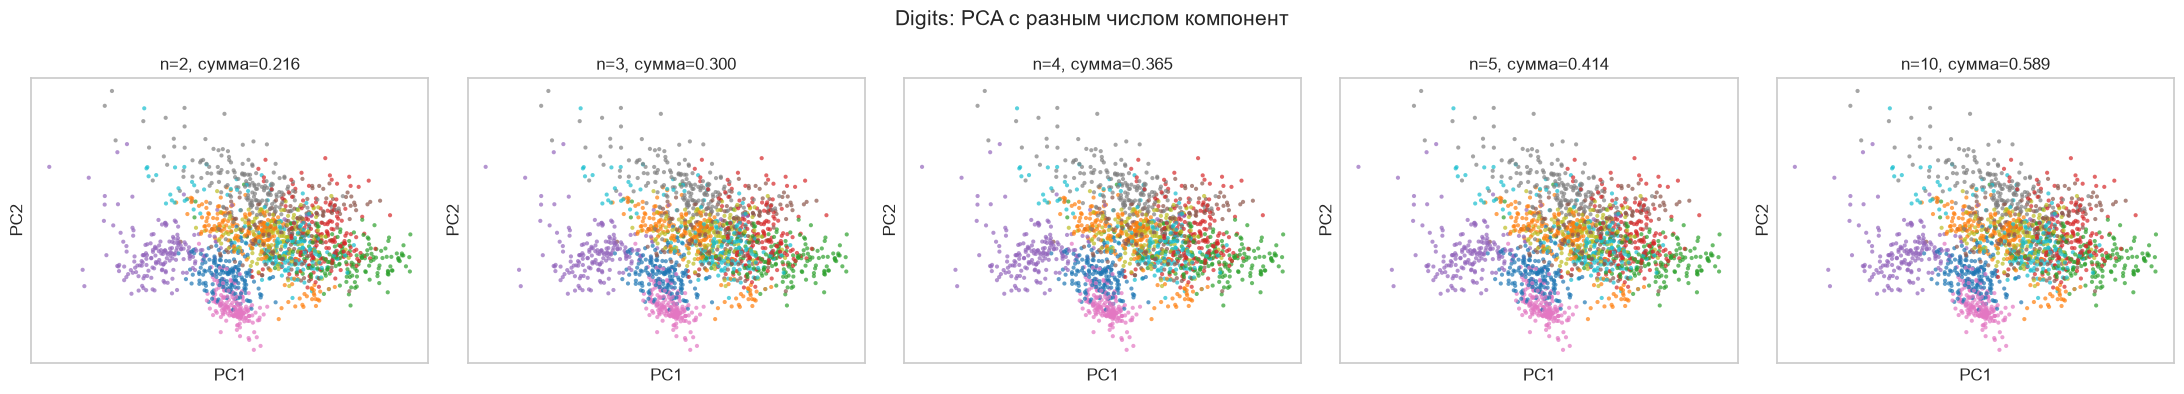

In [22]:
fig, axes = plt.subplots(1, len(n_components), figsize=(22, 4))
for ax, n in zip(axes, n_components):
    pca = PCA(n_components=n, random_state=RANDOM_STATE)
    embedding = pca.fit_transform(X_scaled)
    sns.scatterplot(x=embedding[:, 0], y=embedding[:, 1], hue=y, palette="tab10",
                    s=9, alpha=0.7, linewidth=0, legend=False, ax=ax)
    ax.set_title(f"n={n}, сумма={pca.explained_variance_ratio_.sum():.3f}")
    ax.set(xticks=[], yticks=[], xlabel="PC1", ylabel="PC2")
fig.suptitle("Digits: PCA с разным числом компонент", fontsize=15)
plt.tight_layout()
plt.show()

In [23]:
n_components = [2, 3, 4, 5, 10]

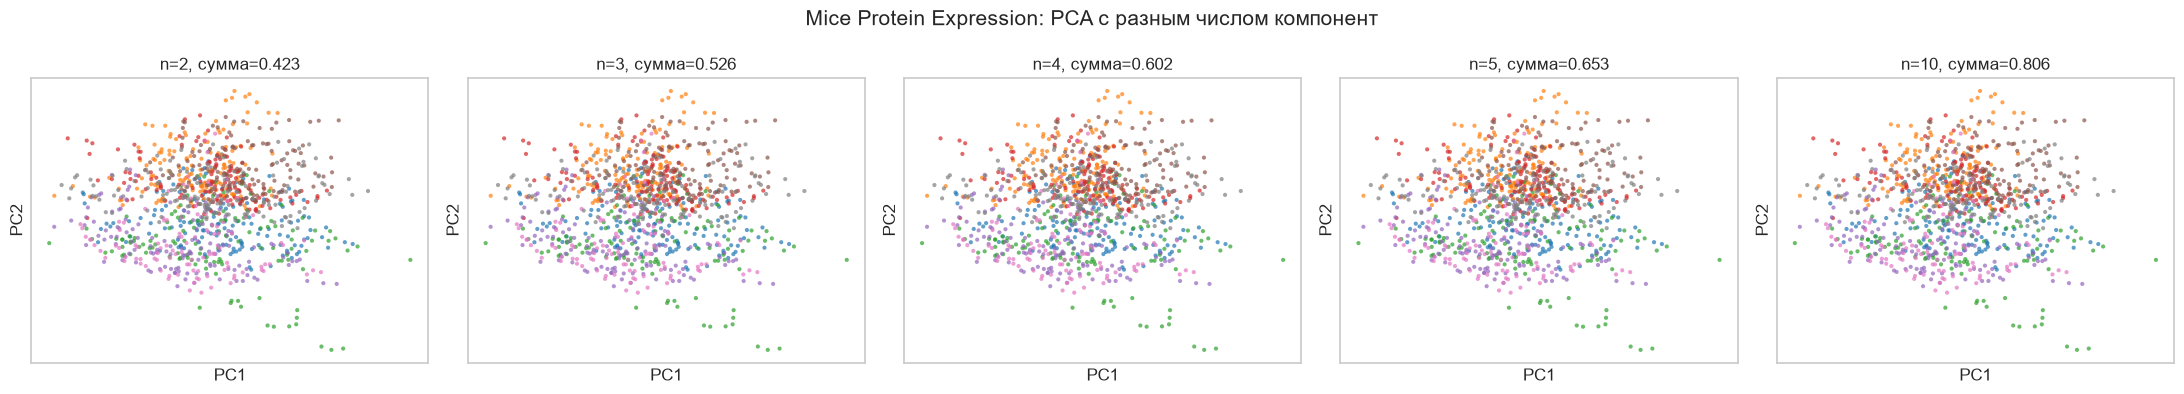

In [24]:
fig, axes = plt.subplots(1, len(n_components), figsize=(22, 4))
for ax, n in zip(axes, n_components):
    pca = PCA(n_components=n, random_state=RANDOM_STATE)
    embedding = pca.fit_transform(my_X_scaled)
    sns.scatterplot(x=embedding[:, 0], y=embedding[:, 1], hue=my_y, palette="tab10",
                    s=9, alpha=0.7, linewidth=0, legend=False, ax=ax)
    ax.set_title(f"n={n}, сумма={pca.explained_variance_ratio_.sum():.3f}")
    ax.set(xticks=[], yticks=[], xlabel="PC1", ylabel="PC2")
fig.suptitle("Mice Protein Expression: PCA с разным числом компонент", fontsize=15)
plt.tight_layout()
plt.show()

In [25]:
# Проверка устойчивости t-SNE при близких значениях perplexity.
stability_rows = []
for name, data, labels in [("Digits", X_scaled, y), ("Mice Protein Expression", my_X_scaled, my_y)]:
    for perplexity in [25, 30, 35]:
        key = (name, perplexity, 200)
        if key in grid_embeddings:
            embedding = grid_embeddings[key]
        else:
            embedding, _ = fit_tsne(data, perplexity, 200)
        stability_rows.append([name, perplexity, silhouette_score(embedding, labels),
                               trustworthiness(data, embedding, n_neighbors=10)])

stability = pd.DataFrame(stability_rows,
                         columns=["Датасет", "Perplexity", "Silhouette", "Trustworthiness@10"])
display(stability.style.format({"Silhouette": "{:.3f}", "Trustworthiness@10": "{:.3f}"}))

best = grid_results.loc[grid_results.groupby("Датасет")["Silhouette"].idxmax()]
print("Лучшие параметры по silhouette score:")
display(best.style.format({"Silhouette": "{:.3f}", "KL divergence": "{:.3f}"}))

,Датасет,Perplexity,Silhouette,Trustworthiness@10
0,Digits,25,0.491,0.986
1,Digits,30,0.480,0.986
2,Digits,35,0.496,0.985
3,Mice Protein Expression,25,-0.021,0.990
4,Mice Protein Expression,30,-0.022,0.990
5,Mice Protein Expression,35,-0.022,0.991


Лучшие параметры по silhouette score:


,Датасет,Perplexity,Learning rate,Silhouette,KL divergence
7,Digits,30,1000,0.501,0.832
16,Mice Protein Expression,5,50,0.007,0.335
